In [ ]:
# Cell 1 - Montage Drive & config des chemins
from google.colab import drive
drive.mount('/content/drive')

# Chemins (modifie si besoin)
DRIVE_ROOT = "/content/drive/MyDrive/ANIP_Challenge"
DATASET_ZIP = f"{DRIVE_ROOT}/Datasets/dataset_tache_3.zip"
DATA_DIR = "/content/dataset_tache_3"  # où on dézippera localement dans Colab
MODELS_DIR = f"{DRIVE_ROOT}/Models"
RESULTS_DIR = f"{DRIVE_ROOT}/Results"

# Création des dossiers si nécessaire
import os
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Drive monté. DATASET_ZIP:", DATASET_ZIP)


Mounted at /content/drive
Drive monté. DATASET_ZIP: /content/drive/MyDrive/ANIP_Challenge/Datasets/dataset_tache_3.zip


In [ ]:
# Cell 2 - Dézipper dataset si besoin
import zipfile, os
if not os.path.exists(DATA_DIR):
    print("Décompression du zip...")
    with zipfile.ZipFile(DATASET_ZIP, 'r') as z:
        z.extractall("/content")
    print("Décompression terminée.")
else:
    print("Dataset déjà présent à", DATA_DIR)


Décompression du zip...
Décompression terminée.


In [ ]:
# Cell 3 - Imports & vérif GPU
import tensorflow as tf
import numpy as np
import pandas as pd
import json
import glob
import random
import math
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from pathlib import Path
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("GPU disponible :", tf.config.list_physical_devices('GPU'))

# Réglage pour précision mixte si GPU compatible (permets accélération)
try:
    from tensorflow.keras import mixed_precision
    mixed_precision.set_global_policy('mixed_float16')
    print("Mixed precision activée.")
except Exception as e:
    print("Mixed precision non activée:", str(e))


TensorFlow version: 2.19.0
GPU disponible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision activée.


In [ ]:
# Cell 4 - Construction d'un DataFrame pour train (labels issus de l'arborescence)
TRAIN_DIR = os.path.join(DATA_DIR, "train")
countries = ["arizona_dl", "esp", "est", "rus"]

rows = []
for country in countries:
    country_dir = os.path.join(TRAIN_DIR, country)
    if not os.path.exists(country_dir):
        print("Attention: dossier manquant", country_dir)
        continue
    # forgery_* et normal
    for label_dir in sorted(os.listdir(country_dir)):
        full_label_dir = os.path.join(country_dir, label_dir)
        if not os.path.isdir(full_label_dir):
            continue
        # définir label numérique : normal -> 0, else forgery -> 1
        label = 0 if label_dir.lower() == "normal" else 1
        # Recup toutes les images (extensions courantes)
        for ext in ("*.png","*.jpg","*.jpeg","*.bmp"):
            for f in glob.glob(os.path.join(full_label_dir, ext)):
                filename = os.path.basename(f)
                rows.append({
                    "filepath": f,
                    "country": country,
                    "label_dir": label_dir,
                    "label": label,
                    "filename": filename
                })

df = pd.DataFrame(rows)
print("Total images train:", len(df))
display(df.groupby(["country","label"]).size())


Total images train: 10000


country     label
arizona_dl  0         500
            1        2000
esp         0         500
            1        2000
est         0         500
            1        2000
rus         0         500
            1        2000
dtype: int64

In [ ]:
# Cell 5 - Aperçu des fichiers gt (pour info) - on ne les utilise pas pour l'instant comme features
print("Exemple de fichiers gt pour 'rus' (si présents):")
gt_paths = glob.glob(os.path.join(TRAIN_DIR, "rus", "gt", "*.json"))
if len(gt_paths)>0:
    for p in gt_paths[:3]:
        with open(p, 'r', encoding='utf-8') as f:
            try:
                d = json.load(f)
                print(p, d)
            except:
                print("Impossible de lire", p)
else:
    print("Aucun fichier gt trouvé ou dossier gt manquant.")


Exemple de fichiers gt pour 'rus' (si présents):
/content/dataset_tache_3/train/rus/gt/generated.photos_v3_0022323_0464159_0410350.json {'country_code': 'RUS', 'surname': 'НАДЕЖДА', 'given_name': 'ПЕТРОВА', 'birthday': '28.03.2000', 'issue_date': '25.03.2022', 'expire_date': '25.03.2032', 'gender': 'ЖЕН', 'patronymic_name': 'АНДРИЕВИЧ', 'place_of_birth': 'ВОРОНЕЖ', 'card_num': '63 41 437543'}
/content/dataset_tache_3/train/rus/gt/generated.photos_v3_0046068.json {'country_code': 'RUS', 'surname': 'АНДРИЙ', 'given_name': 'ПАВЛОВ', 'birthday': '31.12.1997', 'issue_date': '12.04.2024', 'expire_date': '12.04.2034', 'gender': 'МУЖ', 'patronymic_name': 'МИТРОФАНОВИЧ', 'place_of_birth': 'НОВОСИБИРСК', 'card_num': '76 99 328516'}
/content/dataset_tache_3/train/rus/gt/generated.photos_v3_0027256.json {'country_code': 'RUS', 'surname': 'НИКИТА', 'given_name': 'ПАВЛОВ', 'birthday': '27.01.1988', 'issue_date': '22.03.2024', 'expire_date': '22.03.2034', 'gender': 'МУЖ', 'patronymic_name': 'СЕРГЕЕВИ

In [ ]:
# Cell 6 - Split stratifié par country+label pour garder la variété
df['stratify_key'] = df['country'] + "_" + df['label'].astype(str)
train_df, val_df = train_test_split(df, test_size=0.15, random_state=42, stratify=df['stratify_key'])
print("Train:", len(train_df), "Val:", len(val_df))
display(train_df.groupby(["country","label"]).size())
display(val_df.groupby(["country","label"]).size())


Train: 8500 Val: 1500


country     label
arizona_dl  0         425
            1        1700
esp         0         425
            1        1700
est         0         425
            1        1700
rus         0         425
            1        1700
dtype: int64

country     label
arizona_dl  0         75
            1        300
esp         0         75
            1        300
est         0         75
            1        300
rus         0         75
            1        300
dtype: int64

In [ ]:
# Cell 7 - Hyperparamètres & fonctions utilitaires

BATCH_SIZE = 8  # réduit l'usage RAM/GPU — augmente si tu as beaucoup de VRAM
IMG_SIZE = (128, 128)  # compromis: assez grand pour détails de documents
AUTOTUNE = tf.data.AUTOTUNE
EPOCHS = 10
SEED = 42

# Fonctions de parsing et augmentation
def decode_img(img_path):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.convert_image_dtype(img, tf.float32)  # [0,1]
    img = tf.image.resize(img, IMG_SIZE)
    return img

# Data augmentation légère adaptée aux documents (éviter rotations fortes qui cassent le texte)
def augment(img):
    img = tf.image.random_brightness(img, 0.05)
    img = tf.image.random_contrast(img, 0.95, 1.05)
    # petites rotations
    angle = tf.random.uniform([], -0.03, 0.03)  # radians ~ +/- 1.7 deg
    return img

# Build tf.data pipeline
def df_to_dataset(dataframe, shuffle=True, augment_data=False):
    paths = dataframe['filepath'].values
    labels = dataframe['label'].values.astype(np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED)

    def _load(path, label):
        img = decode_img(path)
        if augment_data:
            img = augment(img)
        return img, label

    # 1. Utilisation de tf.py_function
    ds = ds.map(
        lambda p,l: tf.py_function(func=_load, inp=[p,l], Tout=[tf.float32, tf.int32]),
        num_parallel_calls=AUTOTUNE
    )

    # 2. DÉFINITION EXPLICITE DES FORMES (CRITIQUE pour Keras/model.fit)
    def set_shapes(img, label):
        # Image : [Hauteur, Largeur, Channels]
        img.set_shape(IMG_SIZE + (3,))
        # Étiquette : forme scalaire [] (avant one-hot)
        label.set_shape([])
        return img, label

    ds = ds.map(set_shapes, num_parallel_calls=AUTOTUNE)

    # 3. One-hot encoding (le nombre de classes est 2)
    ds = ds.map(lambda x,y: (x, tf.one_hot(y, depth=2)), num_parallel_calls=AUTOTUNE)

    # 4. Batching et Prefetching
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds


In [ ]:
# Cell 8 - Création des datasets
train_ds = df_to_dataset(train_df, shuffle=True, augment_data=True)
val_ds   = df_to_dataset(val_df, shuffle=False, augment_data=False)


In [ ]:
# Cell 9 - Class weights pour aider l'entrainement si classe déséquilibrée
y_train = train_df['label'].values
class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = {i: weight for i, weight in enumerate(class_weights)}
print("Class weights:", class_weights_dict)


Class weights: {0: np.float64(2.5), 1: np.float64(0.625)}


In [ ]:
# Cell 10 (remplacement) — MobileNetV2 compact mais robuste
from tensorflow.keras import layers, models, optimizers, applications, callbacks

def build_light_model(input_shape=(*IMG_SIZE,3), dropout=0.3):
    base = applications.MobileNetV2(include_top=False, weights='imagenet', input_shape=input_shape, pooling='avg')
    base.trainable = False  # on gèle pour la première phase
    x = base.output
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(2, activation='softmax', dtype='float32')(x)
    model = models.Model(inputs=base.input, outputs=outputs)
    return model

light_model_path = os.path.join(MODELS_DIR, "mobilenet_v2_checkpoint.h5")

if os.path.exists(light_model_path):
    print("Checkpoint trouvé, chargement du modèle...")
    model = tf.keras.models.load_model(light_model_path)
else:
    model = build_light_model()

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 64, 64,    │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 64, 64,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 64, 64,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 64, 64,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 64, 64,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 64, 64,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 65, 65,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 32, 32,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 32, 32,    │      2,304 │ block_1_depthwis

 Total params: 2,587,458 (9.87 MB)

 Trainable params: 328,962 (1.25 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

In [ ]:
# Cell 11 (remplacement) — Compilation et callbacks
optimizer = optimizers.Adam(learning_rate=1e-4)
model.compile(optimizer=optimizer,
              loss='categorical_crossentropy',
              metrics=['accuracy'])

cb_ckpt = callbacks.ModelCheckpoint(
    light_model_path,
    monitor='val_accuracy',
    verbose=1,
    save_best_only=False,   # on sauvegarde chaque époque, pas seulement la meilleure
    save_weights_only=False
)
cb_es = callbacks.EarlyStopping(monitor='val_accuracy', patience=6, restore_best_weights=True)
cb_reduce = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7, verbose=1)

callbacks_list = [cb_ckpt, cb_es, cb_reduce]


In [ ]:
# Cell 12 (remplacement) — Phase 1 : base gelée
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights_dict,
    callbacks=callbacks_list
)


Epoch 1/10
1062/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.6542 - loss: 0.6243
Epoch 1: saving model to /content/drive/MyDrive/ANIP_Challenge/Models/mobilenet_v2_checkpoint.h5


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 106s 99ms/step - accuracy: 0.6541 - loss: 0.6243 - val_accuracy: 0.5833 - val_loss: 0.7065 - learning_rate: 2.5000e-05
Epoch 2/10
1062/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.6443 - loss: 0.6357
Epoch 2: saving model to /content/drive/MyDrive/ANIP_Challenge/Models/mobilenet_v2_checkpoint.h5


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 92s 87ms/step - accuracy: 0.6443 - loss: 0.6357 - val_accuracy: 0.5613 - val_loss: 0.7296 - learning_rate: 2.5000e-05
Epoch 3/10
1062/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.6574 - loss: 0.6137
Epoch 3: saving model to /content/drive/MyDrive/ANIP_Challenge/Models/mobilenet_v2_checkpoint.h5


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 89s 84ms/step - accuracy: 0.6574 - loss: 0.6137 - val_accuracy: 0.6180 - val_loss: 0.6656 - learning_rate: 2.5000e-05
Epoch 4/10
1062/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.6406 - loss: 0.6235
Epoch 4: saving model to /content/drive/MyDrive/ANIP_Challenge/Models/mobilenet_v2_checkpoint.h5


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 89s 84ms/step - accuracy: 0.6406 - loss: 0.6235 - val_accuracy: 0.5960 - val_loss: 0.6804 - learning_rate: 2.5000e-05
Epoch 5/10
1062/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.6652 - loss: 0.6149
Epoch 5: saving model to /content/drive/MyDrive/ANIP_Challenge/Models/mobilenet_v2_checkpoint.h5


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 144s 86ms/step - accuracy: 0.6652 - loss: 0.6149 - val_accuracy: 0.5813 - val_loss: 0.7057 - learning_rate: 2.5000e-05
Epoch 6/10
1062/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.6468 - loss: 0.6108
Epoch 6: saving model to /content/drive/MyDrive/ANIP_Challenge/Models/mobilenet_v2_checkpoint.h5



Epoch 6: ReduceLROnPlateau reducing learning rate to 1.249999968422344e-05.
1063/1063 ━━━━━━━━━━━━━━━━━━━━ 88s 83ms/step - accuracy: 0.6468 - loss: 0.6108 - val_accuracy: 0.6180 - val_loss: 0.6677 - learning_rate: 2.5000e-05
Epoch 7/10
1062/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.6573 - loss: 0.6221
Epoch 7: saving model to /content/drive/MyDrive/ANIP_Challenge/Models/mobilenet_v2_checkpoint.h5


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 88s 83ms/step - accuracy: 0.6573 - loss: 0.6221 - val_accuracy: 0.6167 - val_loss: 0.6574 - learning_rate: 1.2500e-05
Epoch 8/10
1062/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.6538 - loss: 0.6158
Epoch 8: saving model to /content/drive/MyDrive/ANIP_Challenge/Models/mobilenet_v2_checkpoint.h5


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 91s 86ms/step - accuracy: 0.6538 - loss: 0.6158 - val_accuracy: 0.5933 - val_loss: 0.6893 - learning_rate: 1.2500e-05
Epoch 9/10
1063/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.6489 - loss: 0.6134
Epoch 9: saving model to /content/drive/MyDrive/ANIP_Challenge/Models/mobilenet_v2_checkpoint.h5


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 89s 83ms/step - accuracy: 0.6489 - loss: 0.6134 - val_accuracy: 0.6100 - val_loss: 0.6708 - learning_rate: 1.2500e-05


In [ ]:
# Cell 13 (remplacement) — Fine-tuning avec reprise automatique
if os.path.exists(light_model_path):
    print("Reprise depuis le dernier checkpoint pour fine-tuning.")
    model = tf.keras.models.load_model(light_model_path)

# Débloquer le dernier tiers du backbone MobileNetV2
base = None
for layer in model.layers:
    if isinstance(layer, tf.keras.Model):
        base = layer
        break

if base is not None:
    total_layers = len(base.layers)
    unfreeze_from = int(total_layers * 0.7)
    for i, layer in enumerate(base.layers):
        layer.trainable = i >= unfreeze_from
    print(f"Débloqué depuis la couche {unfreeze_from}/{total_layers}.")
else:
    print("Backbone non identifié, fine-tuning sauté.")

# Recompile avec learning rate plus petit
model.compile(optimizer=optimizers.Adam(learning_rate=5e-6),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights_dict,
    callbacks=callbacks_list
)


Reprise depuis le dernier checkpoint pour fine-tuning.


Backbone non identifié, fine-tuning sauté.
Epoch 1/10
1063/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.6498 - loss: 0.6144
Epoch 1: saving model to /content/drive/MyDrive/ANIP_Challenge/Models/mobilenet_v2_checkpoint.h5


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 163s 127ms/step - accuracy: 0.6498 - loss: 0.6144 - val_accuracy: 0.5980 - val_loss: 0.6841 - learning_rate: 5.0000e-06
Epoch 2/10
1062/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.6585 - loss: 0.6017
Epoch 2: saving model to /content/drive/MyDrive/ANIP_Challenge/Models/mobilenet_v2_checkpoint.h5


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 93s 87ms/step - accuracy: 0.6585 - loss: 0.6017 - val_accuracy: 0.6220 - val_loss: 0.6587 - learning_rate: 5.0000e-06
Epoch 3/10
1062/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.6603 - loss: 0.6081
Epoch 3: saving model to /content/drive/MyDrive/ANIP_Challenge/Models/mobilenet_v2_checkpoint.h5


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 104s 98ms/step - accuracy: 0.6603 - loss: 0.6081 - val_accuracy: 0.6060 - val_loss: 0.6725 - learning_rate: 5.0000e-06
Epoch 4/10
1062/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.6533 - loss: 0.6152
Epoch 4: saving model to /content/drive/MyDrive/ANIP_Challenge/Models/mobilenet_v2_checkpoint.h5


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 98s 92ms/step - accuracy: 0.6533 - loss: 0.6152 - val_accuracy: 0.6060 - val_loss: 0.6704 - learning_rate: 5.0000e-06
Epoch 5/10
1062/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.6457 - loss: 0.6072
Epoch 5: saving model to /content/drive/MyDrive/ANIP_Challenge/Models/mobilenet_v2_checkpoint.h5



Epoch 5: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-06.
1063/1063 ━━━━━━━━━━━━━━━━━━━━ 137s 87ms/step - accuracy: 0.6457 - loss: 0.6072 - val_accuracy: 0.6067 - val_loss: 0.6683 - learning_rate: 5.0000e-06
Epoch 6/10
1062/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.6678 - loss: 0.6014
Epoch 6: saving model to /content/drive/MyDrive/ANIP_Challenge/Models/mobilenet_v2_checkpoint.h5


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 93s 87ms/step - accuracy: 0.6678 - loss: 0.6014 - val_accuracy: 0.6167 - val_loss: 0.6661 - learning_rate: 2.5000e-06
Epoch 7/10
1062/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.6548 - loss: 0.6107
Epoch 7: saving model to /content/drive/MyDrive/ANIP_Challenge/Models/mobilenet_v2_checkpoint.h5


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 144s 89ms/step - accuracy: 0.6548 - loss: 0.6107 - val_accuracy: 0.6033 - val_loss: 0.6790 - learning_rate: 2.5000e-06
Epoch 8/10
1062/1063 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.6510 - loss: 0.6413
Epoch 8: saving model to /content/drive/MyDrive/ANIP_Challenge/Models/mobilenet_v2_checkpoint.h5



Epoch 8: ReduceLROnPlateau reducing learning rate to 1.249999968422344e-06.
1063/1063 ━━━━━━━━━━━━━━━━━━━━ 93s 87ms/step - accuracy: 0.6510 - loss: 0.6413 - val_accuracy: 0.6087 - val_loss: 0.6746 - learning_rate: 2.5000e-06


188/188 ━━━━━━━━━━━━━━━━━━━━ 18s 97ms/step - accuracy: 0.5942 - loss: 0.6738
Validation loss: 0.6587 - Validation acc: 0.6220


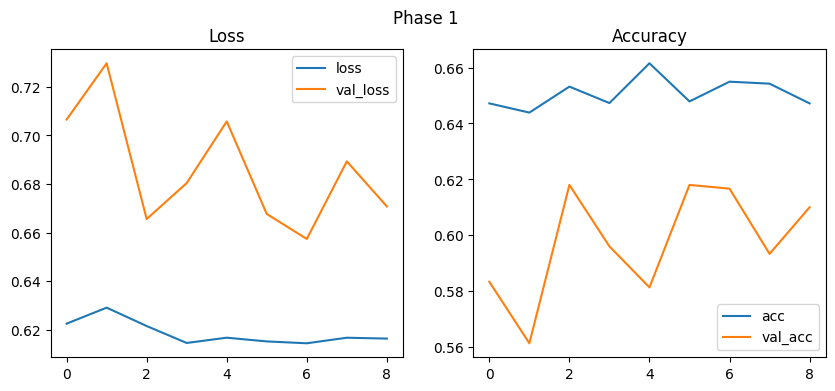

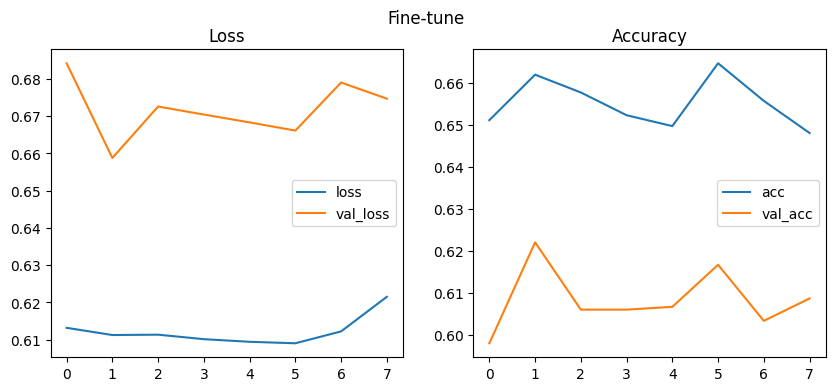

In [ ]:
# Cell 14 - Évaluation & courbes
val_loss, val_acc = model.evaluate(val_ds)
print(f"Validation loss: {val_loss:.4f} - Validation acc: {val_acc:.4f}")

# Tracer les courbes si history présent
def plot_history(h, title="history"):
    if not h:
        return
    plt.figure(figsize=(10,4))
    plt.subplot(1,2,1)
    plt.plot(h.history.get('loss',[]), label='loss')
    plt.plot(h.history.get('val_loss',[]), label='val_loss')
    plt.legend()
    plt.title('Loss')
    plt.subplot(1,2,2)
    plt.plot(h.history.get('accuracy',[]), label='acc')
    plt.plot(h.history.get('val_accuracy',[]), label='val_acc')
    plt.legend()
    plt.title('Accuracy')
    plt.suptitle(title)
    plt.show()

plot_history(history, "Phase 1")
plot_history(history_finetune, "Fine-tune")


In [ ]:
# Cell 15 - Préparer test DataFrame
TEST_DIR = os.path.join(DATA_DIR, "test")
test_rows = []
for country in countries:
    country_dir = os.path.join(TEST_DIR, country)
    if not os.path.exists(country_dir):
        print("Test dossier manquant:", country_dir)
        continue
    for ext in ("*.png","*.jpg","*.jpeg","*.bmp"):
        for f in glob.glob(os.path.join(country_dir, ext)):
            test_rows.append({
                "filepath": f,
                "country": country,
                "filename": os.path.basename(f)
            })
test_df = pd.DataFrame(test_rows)
print("Total images test:", len(test_df))
test_df.head()


Total images test: 200


,filepath,country,filename
0,/content/dataset_tache_3/test/arizona_dl/gener...,arizona_dl,generated.photos_v3_0161565.png
1,/content/dataset_tache_3/test/arizona_dl/gener...,arizona_dl,generated.photos_v3_0165709_0943725_0093934.png
2,/content/dataset_tache_3/test/arizona_dl/gener...,arizona_dl,generated.photos_v3_0159600.png
3,/content/dataset_tache_3/test/arizona_dl/gener...,arizona_dl,generated.photos_v3_0165492.png
4,/content/dataset_tache_3/test/arizona_dl/gener...,arizona_dl,generated.photos_v3_0165010.png


In [ ]:
# Cell 16 - Inférence et création du CSV final
def predict_on_df(model, df, batch_size=BATCH_SIZE):
    results = []
    for i in range(0, len(df), batch_size):
        batch = df.iloc[i:i+batch_size]
        paths = batch['filepath'].tolist()
        imgs = [decode_img(p) for p in paths]
        imgs = tf.stack(imgs, axis=0)
        preds = model.predict(imgs, verbose=0)
        for j, p in enumerate(preds):
            pred_label = int(np.argmax(p))
            confidence = float(np.max(p))
            results.append({
                "filepath": batch.iloc[j]['filepath'],
                "country": batch.iloc[j]['country'],
                "filename": batch.iloc[j]['filename'],
                "prediction": pred_label,
                "confidence": confidence
            })
    return pd.DataFrame(results)

test_results_df = predict_on_df(model, test_df)
print("Inférence terminée. Aperçu:")
display(test_results_df.head())

# Sauvegarde CSV
csv_out = os.path.join(RESULTS_DIR, "inference_test.csv")
test_results_df.to_csv(csv_out, index=False)
print("CSV sauvegardé dans:", csv_out)


Inférence terminée. Aperçu:


,filepath,country,filename,prediction,confidence
0,/content/dataset_tache_3/test/arizona_dl/gener...,arizona_dl,generated.photos_v3_0161565.png,0,0.754396
1,/content/dataset_tache_3/test/arizona_dl/gener...,arizona_dl,generated.photos_v3_0165709_0943725_0093934.png,1,0.877819
2,/content/dataset_tache_3/test/arizona_dl/gener...,arizona_dl,generated.photos_v3_0159600.png,1,0.557106
3,/content/dataset_tache_3/test/arizona_dl/gener...,arizona_dl,generated.photos_v3_0165492.png,1,0.899707
4,/content/dataset_tache_3/test/arizona_dl/gener...,arizona_dl,generated.photos_v3_0165010.png,1,0.574437


CSV sauvegardé dans: /content/drive/MyDrive/ANIP_Challenge/Results/inference_test.csv


In [23]:
# Cell 17 - Sauvegarder le modèle final (keras)
final_model_path = os.path.join(MODELS_DIR, "final_model.keras")
# Si mixed precision, sauvegarde en sauvegardant les poids et l'architecture (h5).
model.save(final_model_path, include_optimizer=False)
print("Modèle sauvegardé à:", final_model_path)


Modèle sauvegardé à: /content/drive/MyDrive/ANIP_Challenge/Models/final_model.keras
